In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
def test_model(model, dataset):
    y_pred = model.predict(dataset, verbose=0)
    y_true = np.concatenate([y for x, y in dataset], axis=0)
    array = multilabel_confusion_matrix(y_true, y_pred.round())[1]
    return array

In [4]:
train_ds, valid_ds = tf.keras.utils.image_dataset_from_directory(
    directory='./data/images_64_train/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.2,
    subset='both',
    seed=42
)
test_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_64_test/',
    labels='inferred',
    label_mode='categorical',
    # label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    seed=42,
    shuffle=False
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train_ds = train_ds.map(process)
valid_ds = valid_ds.map(process)
test_ds = test_ds.map(process)

Found 4992 files belonging to 2 classes.
Using 3994 files for training.
Using 998 files for validation.
Found 1236 files belonging to 2 classes.


In [5]:
# #Correct model
# model = keras.models.Sequential()
# model.add(keras.Input(shape=(64,64,3)))
# model.add(layers.Conv2D(filters=8,kernel_size=8, 
#                         activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Flatten())
# model.add(layers.Dense(units=32, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))

# model.add(layers.Dense(units=1, activation="sigmoid"))

model = keras.models.Sequential()
model.add(keras.Input(shape=(64,64,3)))
model.add(layers.Conv2D(filters=8, kernel_size=7, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dense(units=2, activation='softmax'))


model.compile(
        loss=tf.keras.losses.categorical_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.categorical_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_categorical_accuracy", patience=5)

In [6]:
history = model.fit(
    train_ds, 
    epochs=50, 
    validation_data=valid_ds, 
    callbacks=[stop_early],
    # class_weight= {0: 0.9, 1: 1}
    )

Epoch 1/50
250/250 [==============================] - 8s 14ms/step - loss: 0.4776 - categorical_accuracy: 0.7892 - val_loss: 0.3203 - val_categorical_accuracy: 0.8798
Epoch 2/50
250/250 [==============================] - 3s 13ms/step - loss: 0.3218 - categorical_accuracy: 0.8783 - val_loss: 0.2607 - val_categorical_accuracy: 0.9028
Epoch 3/50
250/250 [==============================] - 3s 13ms/step - loss: 0.2515 - categorical_accuracy: 0.9096 - val_loss: 0.2281 - val_categorical_accuracy: 0.9088
Epoch 4/50
250/250 [==============================] - 3s 13ms/step - loss: 0.1969 - categorical_accuracy: 0.9326 - val_loss: 0.2652 - val_categorical_accuracy: 0.9188
Epoch 5/50
250/250 [==============================] - 3s 13ms/step - loss: 0.1810 - categorical_accuracy: 0.9374 - val_loss: 0.1860 - val_categorical_accuracy: 0.9369
Epoch 6/50
250/250 [==============================] - 3s 14ms/step - loss: 0.1560 - categorical_accuracy: 0.9447 - val_loss: 0.2003 - val_categorical_accuracy: 0.935

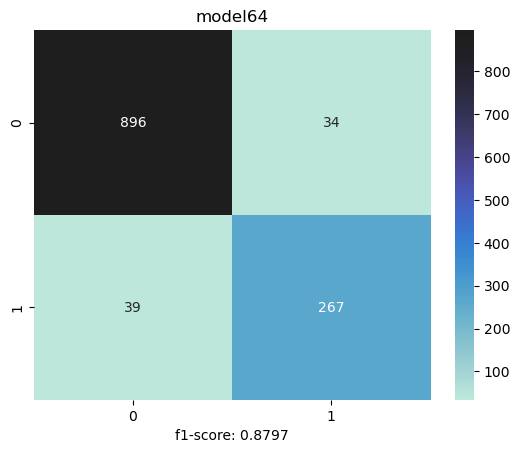

In [8]:
array = test_model(model, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.savefig('./documentation/model64.png')
plt.show()

In [9]:
model.save("./trained_models/model64_class")

INFO:tensorflow:Assets written to: ./trained_models/model64_cat\assets


INFO:tensorflow:Assets written to: ./trained_models/model64_cat\assets


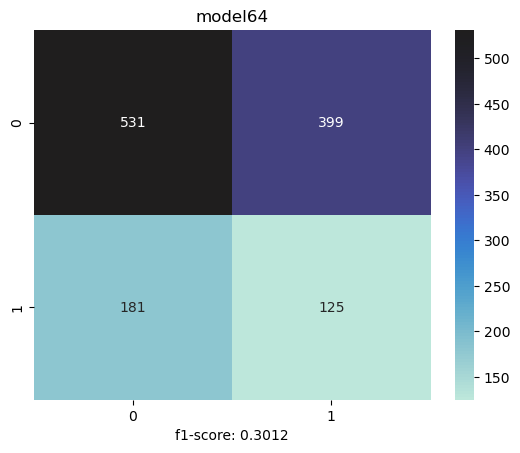

In [5]:
saved_model64 = keras.models.load_model("./trained_models/model64_test/")
# saved_model64.save("./trained_models/model64_2")
array = test_model(saved_model64, test_ds)
f1= (2*array[1][1])/(2*array[1][1]+array[0][1]+array[1][0])

sn.heatmap(array, annot=True, center=array[0][0], fmt='g')
plt.title('model64')
plt.xlabel(f'f1-score: {round(f1,4)}')
plt.show()